# Clase 10 — Aprender de registros: imitar y RL offline

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Pomerleau (1988, ALVINN), Ross, Gordon y Bagnell (2011, DAgger), Levine, Kumar, Tucker y Fu (2020, tutorial de RL offline), y en Stanford CS224R, clases 2 (imitación) y 7 (RL offline), y CS234 (Brunskill), clase 7.

**La pregunta de hoy:** si tenés las partidas grabadas de alguien que sabe salir de la cueva, ¿alcanza con copiarlo? ¿Y si las partidas son de gente que a veces sabe y a veces no?

Hasta ahora el agente aprendía **jugando**: probaba, se equivocaba y volvía a probar. Hoy no juega: recibe un montón de **partidas grabadas** y tiene que arreglarse con eso. Vamos a ver:

1. **Partidas grabadas**: las de un experto y las de jugadores que juegan casi al azar.
2. **Clonación de comportamiento**: copiar la acción del experto en cada casilla.
3. **Errores compuestos**: con el piso resbaloso, la copia llega adonde el experto nunca fue.
4. **DAgger**: preguntarle al experto justo ahí.
5. **Q-learning offline**: el Q-learning de la clase 6 sobre un conjunto fijo, sin jugar.
6. **El cambio de distribución**: cuánto valen las acciones que nunca aparecen en los registros.
7. **Experto contra mezclado**: imitar, imitar filtrando las mejores partidas, o RL offline.

Y un ejercicio: cambiar cuántas partidas hay y qué tan buenas son.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda menos de un minuto.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Importamos la cueva y las bibliotecas de siempre, y fijamos una semilla. Las convenciones son las de las clases 3 a 6: **+1 al entrar a la salida**, la salida es absorbente y vale 0, el primer paso no se descuenta y $\gamma = 0{,}99$. Las partidas duran como mucho 200 pasos, como en el juego.

La cueva de hoy tiene el **piso un poco resbaloso** de la clase 4: con probabilidad `SLIP = 0.1` el jugador se resbala hacia un costado (mitad a cada lado). Así, aunque el experto juegue siempre igual, sus partidas no son todas iguales.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA)
GAMMA = 0.99
SLIP = 0.1
env = CaveEnv(slip=SLIP, max_steps=200)
SEMILLAS = range(10)          # para los promedios: 10 conjuntos de partidas distintos

La celda siguiente define las **herramientas**. Está plegada: no hace falta leerla, solo ejecutarla.

Una aclaración importante: las funciones que **graban** partidas (`grabar`, `jugar_politica`) solo usan `env.reset` y `env.step`, como un jugador. Las que **aprenden** (`copia_mas_frecuente`, `dagger`, `q_offline`) solo miran los registros. El mapa (`env.P`, `env.R`) lo usan dos funciones: `iteracion_de_valor`, que nos da el **experto** (la política óptima de la clase 4), y `medir`, que calcula de forma exacta, sin sortear partidas, la probabilidad de salir en 200 pasos y el retorno esperado de una política. Así las comparaciones no dependen de la suerte de unas pocas partidas de prueba.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})
COL_EXP, COL_COPIA, COL_DADO, COL_MIX, COL_OFF, COL_FILT = COLORES[0], COLORES[1], COLORES[3], COLORES[4], COLORES[2], COLORES[6]


# ---------- la respuesta correcta (esto SÍ usa el mapa) ----------
def iteracion_de_valor(env, gamma=GAMMA, tol=1e-12):
    """Clase 4: V(s) <- max_a [R(s,a) + γ Σ P(s'|s,a) V(s')]. Devuelve V* y Q*."""
    V = np.zeros(env.nS)
    while True:
        V_nuevo = (env.R + gamma * env.P @ V).max(axis=1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            return V_nuevo, env.R + gamma * env.P @ V_nuevo
        V = V_nuevo


def como_tabla(pol):
    """Una flecha por casilla -> tabla pi[s, a] de ceros y unos."""
    pol = np.asarray(pol)
    return np.eye(4)[pol] if pol.ndim == 1 else pol


def medir(env, pi, cubiertas=None, T=200, gamma=GAMMA):
    """Mide una política con el mapa, de forma exacta (sin sortear partidas): sigue la distribución de dónde está
    el jugador paso a paso durante T pasos. Devuelve un diccionario con
      exito    = probabilidad de llegar a la salida en T pasos,
      retorno  = retorno esperado desde S (+1 al entrar, descontado; es V^π(S)),
      fuera    = pasos esperados en casillas sin ejemplos (si se pasa 'cubiertas'),
      pisa     = probabilidad de pisar alguna casilla sin ejemplos,
      masa     = probabilidad de estar en una casilla sin ejemplos en cada paso t."""
    pi = como_tabla(pi)
    Ppi = np.einsum("sa,sat->st", pi, env.P)
    d = np.zeros(env.nS); d[env.start] = 1.0
    nuevas = np.zeros(env.nS); nuevas[env.start] = 1.0       # para 'pisa': cadena que se detiene al pisar lo no cubierto
    fuera_m = None
    if cubiertas is not None:
        fuera_m = ~np.asarray(cubiertas, bool); fuera_m[env.goal] = False
    ret, antes, fuera, pisa, masa = 0.0, 0.0, 0.0, 0.0, []
    for t in range(1, T + 1):
        d = d @ Ppi
        llega = d[env.goal] - antes; antes = d[env.goal]
        ret += gamma ** (t - 1) * llega
        if fuera_m is not None:
            masa.append(d[fuera_m].sum()); fuera += d[fuera_m].sum()
            nuevas = nuevas @ Ppi
            pisa += nuevas[fuera_m].sum(); nuevas[fuera_m] = 0.0
    return {"exito": float(d[env.goal]), "retorno": float(ret), "fuera": float(fuera), "pisa": float(pisa),
            "masa": np.array(masa)}


# ---------- grabar partidas: solo env.reset y env.step ----------
def jugar(env, elegir, rng, max_pasos=200):
    """Una partida desde S. elegir(s, rng) devuelve la acción. Devuelve la lista de pasos (s, a, r, s', llegó)."""
    s = env.reset(); pasos = []
    for _ in range(max_pasos):
        a = elegir(s, rng)
        s2, r, fin, info = env.step(a)
        pasos.append((s, a, r, s2, info["reached_goal"]))
        s = s2
        if info["reached_goal"]:
            break
    return pasos


def grabar(env, pol, eps, n, semilla):
    """n partidas de un jugador que con prob. 1−ε juega la flecha del experto y con prob. ε cualquiera de las 4."""
    rng = np.random.default_rng(semilla); env.rng = np.random.default_rng(10_000 + semilla)
    def elegir(s, rng):
        return int(rng.integers(4)) if rng.random() < eps else int(pol[s])
    return [jugar(env, elegir, rng) for _ in range(n)]


def jugar_politica(env, pi, n, semilla):
    """n partidas siguiendo una tabla pi[s, a] (si tiene varias acciones posibles, sortea)."""
    pi = como_tabla(pi); rng = np.random.default_rng(semilla); env.rng = np.random.default_rng(20_000 + semilla)
    return [jugar(env, lambda s, r: int(r.choice(4, p=pi[s])), rng) for _ in range(n)]


def camino(partida):
    return [partida[0][0]] + [x[3] for x in partida]


def retorno(partida, gamma=GAMMA):
    """+1 al entrar a la salida, descontado: γ^(pasos − 1). 0 si no llegó."""
    return gamma ** (len(partida) - 1) if partida[-1][4] else 0.0


def conteos(env, partidas):
    """C[s, a] = cuántas veces aparece la acción a en la casilla s en los registros."""
    C = np.zeros((env.nS, env.nA))
    for p in partidas:
        for s, a, *_ in p:
            C[s, a] += 1
    return C


# ---------- imitar (clonación de comportamiento) ----------
def copia_mas_frecuente(C, sin_datos="arriba"):
    """En cada casilla, la acción que más aparece en los registros (argmax de los conteos).
    Donde no hay ejemplos, las cuatro empatan en 0 y argmax devuelve la primera: ↑ ('arriba').
    Con sin_datos='dado', ahí sortea una de las cuatro."""
    pi = np.eye(4)[C.argmax(axis=1)]
    if sin_datos == "dado":
        pi[C.sum(axis=1) == 0] = 0.25
    return pi


def copia_proporcional(C):
    """La copia fiel: en cada casilla, cada acción con la frecuencia con que aparece en los registros
    (lo que aprende un clasificador con softmax). Donde no hay ejemplos, ↑ como la otra."""
    pi = np.eye(4)[C.argmax(axis=1)]
    vis = C.sum(axis=1) > 0
    pi[vis] = C[vis] / C[vis].sum(axis=1, keepdims=True)
    return pi


def mejores(partidas, frac=0.25):
    """Filtrar: la fracción de partidas con mayor retorno (solo las que llegaron)."""
    orden = sorted(partidas, key=retorno, reverse=True)
    return [p for p in orden[:max(1, int(round(frac * len(partidas))))] if retorno(p) > 0]


def dagger(env_juego, pol_experto, partidas, rondas, n_por_ronda, semilla, beta=0.5, sin_datos="arriba"):
    """Ronda 0: la copia de las partidas grabadas. En cada ronda k = 1, 2, ...: se juegan n partidas en las que
    maneja el experto con prob. beta^k y la copia con prob. 1 − beta^k (Ross et al. mezclan así: al principio el
    experto todavía ayuda, después casi nada); en cada casilla que se pisó se le pregunta al experto qué haría,
    se suman esos ejemplos a la tabla y se vuelve a copiar.
    Devuelve la lista de copias (una por ronda), la tabla de conteos de cada ronda y las etiquetas pedidas por ronda."""
    C = conteos(env_juego, partidas); copias, tablas, etiquetas = [], [], []
    experto = np.eye(4)[pol_experto]
    for k in range(rondas + 1):
        pi = copia_mas_frecuente(C, sin_datos)
        copias.append(pi); tablas.append(C.copy())
        if k == rondas:
            break
        b = beta ** (k + 1) if beta > 0 else 0.0
        n_et = 0
        for p in jugar_politica(env_juego, b * experto + (1 - b) * pi, n_por_ronda, semilla=1000 * semilla + k):
            for s, *_ in p:
                C[s, pol_experto[s]] += 1          # la etiqueta la pone el experto, no la copia
                n_et += 1
        etiquetas.append(n_et)
    return copias, tablas, etiquetas


# ---------- RL offline: Q-learning sobre un conjunto fijo ----------
def q_offline(env, partidas, q0=0.0, alfa=0.1, barridos=60, semilla=0, gamma=GAMMA, solo_vistas=False):
    """Q-learning de la clase 6, pero sin jugar: recorre las transiciones grabadas, una y otra vez, en orden al azar.
        Q(s,a) += α [r + γ max_a' Q(s',a') − Q(s,a)]      (al entrar a la salida: objetivo = r)
    q0: con qué valor arranca la tabla (un número o una tabla). solo_vistas=True: el max solo mira las acciones
    que aparecen en los registros en s' (la idea de los métodos offline 'conservadores').
    Devuelve Q y la máscara visto[s, a]."""
    rng = np.random.default_rng(semilla)
    Q = (np.full((env.nS, env.nA), float(q0)) if np.isscalar(q0) else np.array(q0, float)).copy()
    Q[env.goal] = 0.0
    visto = conteos(env, partidas) > 0
    trans = [x for p in partidas for x in p]
    Ql = Q.tolist()
    acc = [[a for a in range(env.nA) if visto[s, a]] or list(range(env.nA)) for s in range(env.nS)]
    for _ in range(barridos):
        for i in rng.permutation(len(trans)):
            s, a, r, s2, llego = trans[i]
            if llego:
                y = r
            elif solo_vistas:
                q2 = Ql[s2]; y = r + gamma * max(q2[b] for b in acc[s2])
            else:
                y = r + gamma * max(Ql[s2])
            Ql[s][a] += alfa * (y - Ql[s][a])
    return np.array(Ql), visto


def politica_de_Q(Q, visto=None, solo_vistas=False):
    """La flecha de mayor Q en cada casilla (con solo_vistas, entre las acciones de los registros).
    En casillas sin ningún registro, argmax de una fila que nunca cambió."""
    Qm = Q.copy()
    if solo_vistas:
        hay = visto.any(axis=1)
        Qm[hay] = np.where(visto[hay], Q[hay], -np.inf)
    return np.eye(4)[Qm.argmax(axis=1)]


def coser(partidas, cam):
    """Parte el camino cam en tramos, cada uno copiado de una sola partida grabada (el más largo posible desde donde
    se está). Devuelve la lista de (desde, hasta, partida) y el tramo seguido más largo que aparece en una sola partida."""
    T = list(zip(cam[:-1], cam[1:]))
    pasos = [[(x, y) for (x, a, r, y, g) in p] for p in partidas]

    def largo(i_p, j):                      # tramo más largo de T desde j que aparece seguido en la partida i_p
        tr, mejor = pasos[i_p], 0
        for i in range(len(tr)):
            k = 0
            while i + k < len(tr) and j + k < len(T) and tr[i + k] == T[j + k]:
                k += 1
            mejor = max(mejor, k)
        return mejor
    tramos, j = [], 0
    while j < len(T):
        k, i_p = max((largo(i, j), i) for i in range(len(partidas)))
        if k == 0:
            tramos.append((j, j + 1, None)); j += 1
        else:
            tramos.append((j, j + k, i_p)); j += k
    mas_largo = max(largo(i, j) for i in range(len(partidas)) for j in range(len(T)))
    return tramos, mas_largo


# ---------- dibujos de la cueva ----------
def plot_cave(env, values=None, policy=None, path=None, ax=None, title=None, cmap="magma", clim=None,
              mark=None, numbers=False, fmt="{:.2f}"):
    """env.plot + escala de color elegible (calculada sin la salida), flechas con borde, círculos y números opcionales."""
    ax = env.plot(values=values, policy=policy, path=path, ax=ax, title=title, cmap=cmap)
    if values is not None:
        if clim is None:
            v = np.asarray(values, dtype=float)[np.arange(env.nS) != env.goal]
            v = v[np.isfinite(v)]
            clim = (v.min(), v.max()) if v.size else (0, 1)
            if clim[1] - clim[0] < 1e-12:
                clim = (clim[1] - 1, clim[1])
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    if mark is not None:
        for m in np.atleast_1d(mark):
            r, c = env.free[int(m)]
            ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    if numbers and values is not None:
        for s, (r, c) in enumerate(env.free):
            if np.isfinite(values[s]) and s != env.goal:
                ax.text(c, r + 0.3, fmt.format(values[s]), ha="center", va="center", fontsize=7, color="w",
                        path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    return ax


def flechas(env, ax, pi, casillas, color="cyan", fontsize=11):
    """Dibuja la flecha de la tabla pi (la más probable) solo en las casillas indicadas."""
    pi = como_tabla(pi)
    for s in casillas:
        if s == env.goal:
            continue
        r, c = env.free[s]
        if s == env.start:
            c = c + 0.3                      # que no tape la S
        ax.text(c, r, ACTION_NAMES[int(pi[s].argmax())], ha="center", va="center", color=color, fontsize=fontsize,
                path_effects=[pe.withStroke(linewidth=2.5, foreground="black")])


def partidas_superpuestas(env, partidas, ax, color, titulo, values=None, cmap="viridis", clim=None):
    """Dibuja varias partidas sobre la cueva; cada una corrida un poquito para que se distingan."""
    plot_cave(env, values=values, ax=ax, title=titulo, cmap=cmap, clim=clim)
    n = len(partidas)
    for i, p in enumerate(partidas):
        rc = np.array([env.free[s] for s in camino(p)], dtype=float)
        dx = (i - (n - 1) / 2) * 0.03
        ax.plot(rc[:, 1] + dx, rc[:, 0] + dx, "-", color=color, lw=1.2, alpha=0.6)


def dibujar_camino(env, ax, cam, color, lw=2.5, ls="-", label=None, temblor=0.0, semilla=0):
    """Dibuja un camino; con temblor > 0 corre cada punto un poquito al azar, para que se vean las idas y vueltas."""
    rc = np.array([env.free[s] for s in cam], dtype=float)
    if temblor > 0:
        rc = rc + np.random.default_rng(semilla).uniform(-temblor, temblor, rc.shape)
    ax.plot(rc[:, 1], rc[:, 0], ls, color=color, lw=lw, alpha=0.9, label=label)


def banda(ax, x, y, color, label, ls="-", marker="o"):
    """Promedio sobre semillas y banda de ± 1 desvío."""
    y = np.asarray(y, float); m, sd = y.mean(0), y.std(0)
    ax.plot(x, m, color=color, label=label, ls=ls, marker=marker, ms=5)
    ax.fill_between(x, m - sd, m + sd, color=color, alpha=0.15, lw=0)

## 1. Partidas grabadas

Pensemos en el **modo Jugar** de la página: cada vez que alguien juega, queda grabado qué casilla pisó y qué flecha apretó. Tenemos dos montones de grabaciones:

- **Experto**: alguien que sabe salir. Juega siempre la mejor flecha (la política óptima de la clase 4), pero el piso resbaloso a veces lo saca del camino y tiene que volver.
- **Mezcladas**: jugadores que a veces saben y casi siempre no. En cada paso, con probabilidad $\varepsilon = 0{,}8$ aprietan cualquier flecha y si no, la del experto.

### Paso 1 — El experto

La política óptima se calcula con el mapa, por iteración de valor, como en la clase 4. Es la única vez que el mapa entra en el juego: el experto lo conoce; el que aprende, no.

In [4]:
V_estrella, Q_estrella = iteracion_de_valor(env)
pol_exp = Q_estrella.argmax(axis=1)
ng = np.arange(env.nS) != env.goal            # todas las casillas menos la salida
m_exp = medir(env, pol_exp)

print(f"V*(S) con slip {SLIP} = {V_estrella[env.start]:.4f}")
print(f"el experto sale en 200 pasos con probabilidad {m_exp['exito']:.4f}   retorno esperado = {m_exp['retorno']:.4f}")
print(f"casillas de la cueva (sin la salida): {int(ng.sum())}   pares (casilla, acción): {int(ng.sum()) * 4}")

V*(S) con slip 0.1 = 0.8032
el experto sale en 200 pasos con probabilidad 1.0000   retorno esperado = 0.8032
casillas de la cueva (sin la salida): 59   pares (casilla, acción): 236


### Paso 2 — Grabar partidas

Grabamos 20 partidas de cada tipo. Cada registro es una lista de pasos: casilla, acción, premio, casilla siguiente y si llegó. Para **imitar** solo vamos a usar los dos primeros: los pares (casilla, acción).

In [5]:
N_PARTIDAS = 20
EPS_MIX = 0.8
exp_0 = grabar(env, pol_exp, 0.0, N_PARTIDAS, semilla=SEMILLA)
mix_0 = grabar(env, pol_exp, EPS_MIX, N_PARTIDAS, semilla=SEMILLA)

def resumen(nombre, partidas):
    C = conteos(env, partidas); cub = C.sum(axis=1) > 0
    largos = [len(p) for p in partidas]; llegaron = sum(retorno(p) > 0 for p in partidas)
    print(f"{nombre:10s} partidas = {len(partidas)}   pares (casilla, acción) grabados = {sum(largos):5d}   "
          f"llegaron = {llegaron:2d}   pasos por partida = {np.mean(largos):6.1f}   "
          f"casillas con ejemplos = {int(cub[ng].sum())} de {int(ng.sum())}   pares distintos = {int((C[ng] > 0).sum())} de {int(ng.sum()) * 4}")

resumen("experto", exp_0)
resumen("mezcladas", mix_0)
print("\nlos primeros 8 pasos de la primera partida del experto:")
print("   " + "   ".join(f"{env.free[s]} {ACTION_NAMES[a]}" for s, a, *_ in exp_0[0][:8]))

experto    partidas = 20   pares (casilla, acción) grabados =   451   llegaron = 20   pasos por partida =   22.6   casillas con ejemplos = 22 de 59   pares distintos = 22 de 236
mezcladas  partidas = 20   pares (casilla, acción) grabados =  2534   llegaron = 17   pasos por partida =  126.7   casillas con ejemplos = 45 de 59   pares distintos = 167 de 236

los primeros 8 pasos de la primera partida del experto:
   (1, 1) →   (1, 2) →   (1, 3) →   (1, 4) ↓   (2, 4) ↓   (3, 4) ←   (3, 3) ↓   (4, 3) ↓


### Paso 3 — Dónde hay ejemplos

El color es cuántas veces se pisó cada casilla en las 20 partidas (en escala logarítmica, como el mapa de visitas de la clase 6); las líneas son las partidas. Las casillas negras no aparecen nunca en los registros.

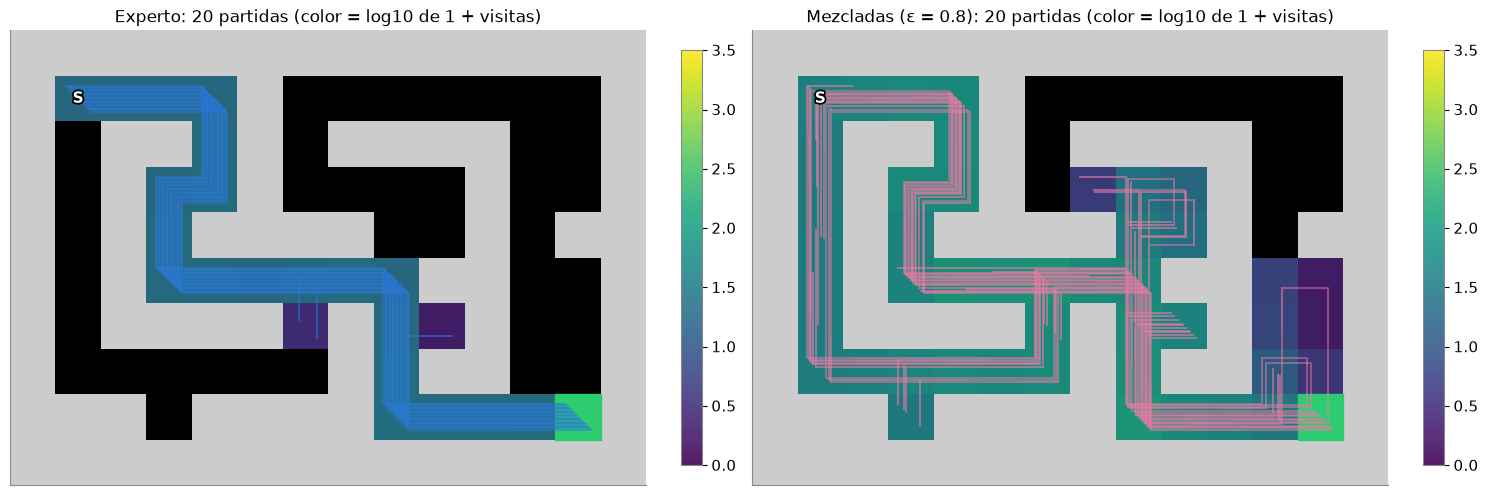

casillas con ejemplos en 10 conjuntos de 20 partidas (de 59):
   experto:   [22, 33, 22, 21, 34, 34, 20, 21, 33, 23]   promedio = 26.3
   mezcladas: [45, 59, 45, 49, 59, 57, 44, 45, 46, 50]   promedio = 49.9


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, partidas, color, nombre in [(axs[0], exp_0, COL_EXP, "Experto"), (axs[1], mix_0, COL_MIX, f"Mezcladas (ε = {EPS_MIX})")]:
    vis = conteos(env, partidas).sum(axis=1)
    vals = np.where(vis > 0, np.log10(1 + vis), np.nan)
    partidas_superpuestas(env, partidas, ax, color, f"{nombre}: 20 partidas (color = log10 de 1 + visitas)",
                          values=vals, cmap="viridis", clim=(0, 3.5))
plt.tight_layout(); plt.show()

cub_exp = [int((conteos(env, grabar(env, pol_exp, 0.0, N_PARTIDAS, sem)).sum(1) > 0)[ng].sum()) for sem in SEMILLAS]
cub_mix = [int((conteos(env, grabar(env, pol_exp, EPS_MIX, N_PARTIDAS, sem)).sum(1) > 0)[ng].sum()) for sem in SEMILLAS]
print(f"casillas con ejemplos en 10 conjuntos de 20 partidas (de {int(ng.sum())}):")
print(f"   experto:   {cub_exp}   promedio = {np.mean(cub_exp):.1f}")
print(f"   mezcladas: {cub_mix}   promedio = {np.mean(cub_mix):.1f}")

Las 20 partidas del experto suman 451 pares (casilla, acción) y tocan **22 de las 59 casillas**: el camino corto y un par de casillas a los costados, adonde lo llevó algún resbalón. Las mezcladas son mucho más largas (126,7 pasos por partida en promedio; 17 de 20 llegaron) y tocan 45 casillas, con flechas de todo tipo: 167 de los 236 pares posibles.

En 10 conjuntos de 20 partidas, el experto toca entre 20 y 34 casillas (26,3 en promedio). Los conjuntos de 33 o 34 son los que tienen alguna partida en la que el experto se resbaló hacia abajo en S y siguió por el pasillo de la izquierda, el otro camino corto. Las mezcladas tocan 49,9 en promedio.

Fíjense que para **imitar** no hace falta saber la recompensa: alcanza con los pares (casilla, acción).

## 2. Clonación de comportamiento

La idea más directa: en cada casilla, hacer **lo que hacía el experto**. Es aprendizaje supervisado (*supervised learning*), como el de la última pestaña de la clase 2: la entrada es la casilla, la etiqueta es la flecha que apretó el experto, y se aprende a predecir la etiqueta. No hace falta la recompensa. Se llama **clonación de comportamiento** (*behavior cloning*); ALVINN (Pomerleau, 1988) aprendió así a manejar una camioneta: una red neuronal miraba la cámara y copiaba el volante del conductor.

### Paso 1 — La tabla de conteos

Con una cueva de 59 casillas, el «clasificador» más simple es una tabla: para cada casilla, cuántas veces aparece cada flecha en los registros.

In [7]:
C_exp = conteos(env, exp_0)
C_mix = conteos(env, mix_0)
cruce = env.pos2s[(5, 6)]
for nombre, C in [("experto", C_exp), ("mezcladas", C_mix)]:
    print(f"{nombre}:")
    for s in [env.start, env.pos2s[(1, 2)], cruce]:
        print(f"   casilla {str(env.free[s]):8s} " + "   ".join(f"{ACTION_NAMES[a]} {int(C[s, a]):3d}" for a in range(4))
              + f"     flecha del experto: {ACTION_NAMES[pol_exp[s]]}")

experto:
   casilla (1, 1)   ↑   0   →  21   ↓   0   ←   0     flecha del experto: →
   casilla (1, 2)   ↑   0   →  21   ↓   0   ←   0     flecha del experto: →
   casilla (5, 6)   ↑   0   →  22   ↓   0   ←   0     flecha del experto: →
mezcladas:
   casilla (1, 1)   ↑   9   →  23   ↓  10   ←  14     flecha del experto: →
   casilla (1, 2)   ↑  14   →  29   ↓   8   ←  12     flecha del experto: →
   casilla (5, 6)   ↑  21   →  40   ↓  26   ←  20     flecha del experto: →


### Paso 2 — La copia

La copia elige en cada casilla la flecha que más aparece (el `argmax` de la fila). Un detalle que va a importar: en una casilla **sin ejemplos** las cuatro flechas empatan en 0, y `argmax` devuelve la primera, **↑**. La copia no sabe qué hacer ahí, pero algo hace.

En el dibujo, las flechas celestes son las de las casillas con ejemplos y las rojas, las de las casillas sin ejemplos.

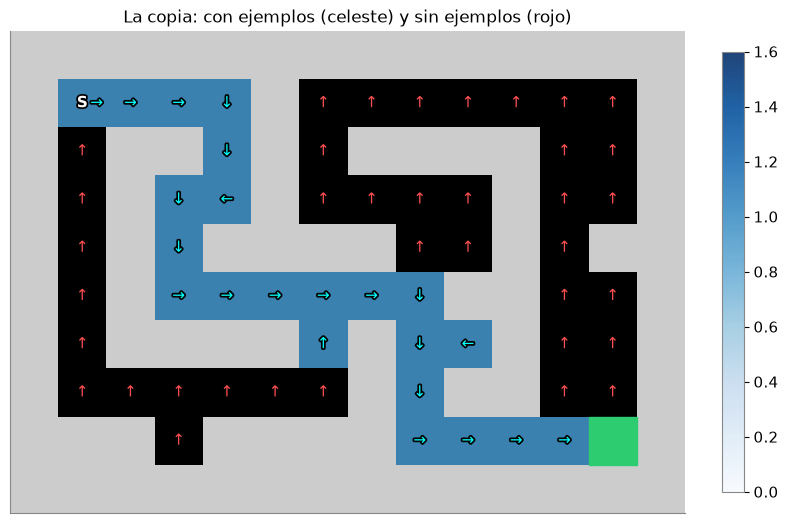

casillas con ejemplos: 22; en 22 de ellas la copia coincide con el experto (100%: sin errores en los datos de entrenamiento)
casillas sin ejemplos: 37; ahí la copia dice ↑ y el experto diría ↑ en 2 de ellas


In [8]:
copia_0 = copia_mas_frecuente(C_exp)
cub_0 = C_exp.sum(axis=1) > 0
iguales = [s for s in np.flatnonzero(cub_0 & ng) if copia_0[s].argmax() == pol_exp[s]]

fig, ax = plt.subplots(figsize=(8, 5.8))
plot_cave(env, values=np.where(cub_0, 1.0, np.nan), ax=ax, cmap="Blues", clim=(0, 1.6),
          title="La copia: con ejemplos (celeste) y sin ejemplos (rojo)")
flechas(env, ax, copia_0, np.flatnonzero(cub_0), color="cyan")
flechas(env, ax, copia_0, np.flatnonzero(~cub_0), color="#ff5050")
plt.tight_layout(); plt.show()

print(f"casillas con ejemplos: {int(cub_0[ng].sum())}; en {len(iguales)} de ellas la copia coincide con el experto "
      f"({len(iguales) / cub_0[ng].sum():.0%}: sin errores en los datos de entrenamiento)")
print(f"casillas sin ejemplos: {int((~cub_0)[ng].sum())}; ahí la copia dice ↑ y el experto diría ↑ en "
      f"{int(sum(pol_exp[s] == 0 for s in np.flatnonzero(~cub_0 & ng)))} de ellas")

### Paso 3 — ¿La copia sale?

Medimos la copia en la misma cueva en la que se grabaron las partidas (slip 0,1), con `medir`, y la comparamos con el experto. Lo repetimos con 10 conjuntos de 20 partidas.

In [9]:
m_copia = medir(env, copia_0, cub_0)
print(f"conjunto 0:  copia sale con prob. {m_copia['exito']:.4f}   retorno = {m_copia['retorno']:.4f}   "
      f"(experto: {m_exp['exito']:.4f} y {m_exp['retorno']:.4f})")

filas = []
for sem in SEMILLAS:
    C = conteos(env, grabar(env, pol_exp, 0.0, N_PARTIDAS, sem))
    m = medir(env, copia_mas_frecuente(C), C.sum(1) > 0)
    filas.append((int((C.sum(1) > 0)[ng].sum()), m["exito"], m["retorno"]))
filas = np.array(filas)
print(f"\n{'conjunto':>9s} {'casillas':>9s} {'sale':>8s} {'retorno':>8s}")
for sem, (c, e, r) in zip(SEMILLAS, filas):
    print(f"{sem:>9d} {int(c):>9d} {e:>8.3f} {r:>8.3f}")
print(f"{'promedio':>9s} {filas[:, 0].mean():>9.1f} {filas[:, 1].mean():>8.3f} {filas[:, 2].mean():>8.3f}"
      f"     experto: {m_exp['exito']:.3f} {m_exp['retorno']:.3f}")

conjunto 0:  copia sale con prob. 0.9474   retorno = 0.7617   (experto: 1.0000 y 0.8032)

 conjunto  casillas     sale  retorno
        0        22    0.947    0.762
        1        33    0.997    0.794
        2        22    0.997    0.794
        3        21    0.947    0.755
        4        34    0.997    0.801
        5        34    0.997    0.801
        6        20    0.947    0.755
        7        21    0.947    0.762
        8        33    0.997    0.794
        9        23    0.997    0.801
 promedio      26.3    0.977    0.782     experto: 1.000 0.803


En las 22 casillas con ejemplos, la copia hace exactamente lo mismo que el experto: como clasificador, no tiene ni un error en sus datos. En las 37 casillas sin ejemplos dice ↑, que coincide con el experto solo en 2.

En la misma cueva de las grabaciones, la copia sale con probabilidad 0,977 en promedio (el experto, siempre). En 4 de los 10 conjuntos sale con 0,947: falla en el 5 % de las partidas, aunque nunca se equivoca donde tiene ejemplos. Lo que le falta no está en las casillas que vio, sino en las que no vio.

## 3. Errores compuestos

La copia es perfecta **donde hay ejemplos**. El problema es llegar adonde no los hay. Basta un resbalón para pisar una casilla que el experto nunca visitó; ahí la copia aprieta ↑, que puede no tener nada que ver con la salida, y se aleja más. Un error lleva a otro: por eso se llaman **errores compuestos** (*compounding errors*).

Para verlo, dejamos la copia del conjunto 0 (grabada con slip 0,1) y la ponemos en cuevas cada vez más resbalosas, como si el piso de prueba no fuera el de las grabaciones.

### Paso 1 — Más resbalón, más casillas sin ejemplos

Para cada slip medimos al experto y a la copia. Además, con la copia, la probabilidad de **pisar alguna casilla sin ejemplos** y cuántos pasos pasa, en promedio, en esas casillas. Agregamos una variante de la copia que, en las casillas sin ejemplos, en vez de ↑ tira un dado.

promedio de 10 conjuntos de 20 partidas del experto (grabadas con slip 0,1):
 slip  experto sale  copia sale  copia+dado  pisa sin ej. copia  pisa sin ej. experto  pasos sin ej. copia  pasos sin ej. experto
  0.0         1.000       1.000       1.000               0.000                 0.000                  0.0                    0.0
  0.1         1.000       0.977       0.998               0.088                 0.088                  4.6                    0.5
  0.2         1.000       0.948       0.995               0.184                 0.184                  9.8                    1.2
  0.3         1.000       0.911       0.990               0.289                 0.289                 16.1                    2.2
  0.4         1.000       0.862       0.983               0.404                 0.404                 23.6                    3.8


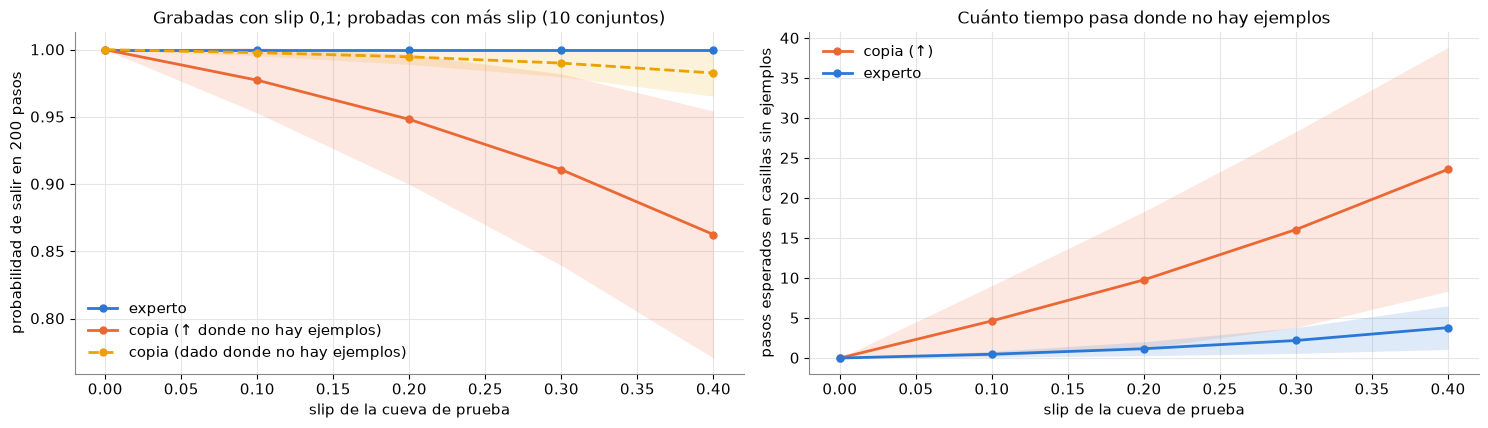

In [10]:
SLIPS = [0.0, 0.1, 0.2, 0.3, 0.4]
res3 = {k: np.zeros((len(SEMILLAS), len(SLIPS))) for k in ["exp", "copia", "dado", "pisa", "pisa_exp", "fuera", "fuera_exp"]}
for i, sem in enumerate(SEMILLAS):
    C = conteos(env, grabar(env, pol_exp, 0.0, N_PARTIDAS, sem)); cub = C.sum(1) > 0
    for j, sl in enumerate(SLIPS):
        e = CaveEnv(slip=sl)
        me, mc, md_ = medir(e, pol_exp, cub), medir(e, copia_mas_frecuente(C), cub), medir(e, copia_mas_frecuente(C, "dado"), cub)
        res3["exp"][i, j], res3["copia"][i, j], res3["dado"][i, j] = me["exito"], mc["exito"], md_["exito"]
        res3["pisa"][i, j], res3["fuera"][i, j], res3["fuera_exp"][i, j] = mc["pisa"], mc["fuera"], me["fuera"]
        res3["pisa_exp"][i, j] = me["pisa"]

print("promedio de 10 conjuntos de 20 partidas del experto (grabadas con slip 0,1):")
print(f"{'slip':>5s} {'experto sale':>13s} {'copia sale':>11s} {'copia+dado':>11s} {'pisa sin ej. copia':>19s} {'pisa sin ej. experto':>21s} "
      f"{'pasos sin ej. copia':>20s} {'pasos sin ej. experto':>22s}")
for j, sl in enumerate(SLIPS):
    print(f"{sl:>5.1f} {res3['exp'][:, j].mean():>13.3f} {res3['copia'][:, j].mean():>11.3f} {res3['dado'][:, j].mean():>11.3f} "
          f"{res3['pisa'][:, j].mean():>19.3f} {res3['pisa_exp'][:, j].mean():>21.3f} {res3['fuera'][:, j].mean():>20.1f} "
          f"{res3['fuera_exp'][:, j].mean():>22.1f}")

fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
banda(axs[0], SLIPS, res3["exp"], COL_EXP, "experto")
banda(axs[0], SLIPS, res3["copia"], COL_COPIA, "copia (↑ donde no hay ejemplos)")
banda(axs[0], SLIPS, res3["dado"], COL_DADO, "copia (dado donde no hay ejemplos)", ls="--")
axs[0].set_xlabel("slip de la cueva de prueba"); axs[0].set_ylabel("probabilidad de salir en 200 pasos")
axs[0].set_title("Grabadas con slip 0,1; probadas con más slip (10 conjuntos)"); axs[0].legend(frameon=False)
banda(axs[1], SLIPS, res3["fuera"], COL_COPIA, "copia (↑)")
banda(axs[1], SLIPS, res3["fuera_exp"], COL_EXP, "experto")
axs[1].set_xlabel("slip de la cueva de prueba"); axs[1].set_ylabel("pasos esperados en casillas sin ejemplos")
axs[1].set_title("Cuánto tiempo pasa donde no hay ejemplos"); axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()

Con el piso de las grabaciones (slip 0,1), la copia pisa alguna casilla sin ejemplos con probabilidad 0,088 y sale con 0,977. Con slip 0,4 pisa con 0,404 y sale con 0,862; el experto sigue saliendo siempre.

La probabilidad de pisar una casilla sin ejemplos es **la misma** para los dos (las columnas «pisa sin ej.» son iguales): la copia es idéntica al experto hasta ese momento. La diferencia es qué pasa después. El experto sabe volver y pasa ahí 3,8 pasos en promedio (con slip 0,4); la copia, 23,6. Con un dado en lugar de ↑ la copia sale casi siempre (0,983 con slip 0,4): en esta cueva chica, deambular al azar termina encontrando el camino, pero apretar siempre ↑ puede dejarla trabada contra una pared.

### Paso 2 — El desvío que se agranda

Seguimos, paso a paso, la probabilidad de estar en una casilla sin ejemplos, con slip 0,3, para el conjunto 0. Y dibujamos una partida de la copia que no llega.

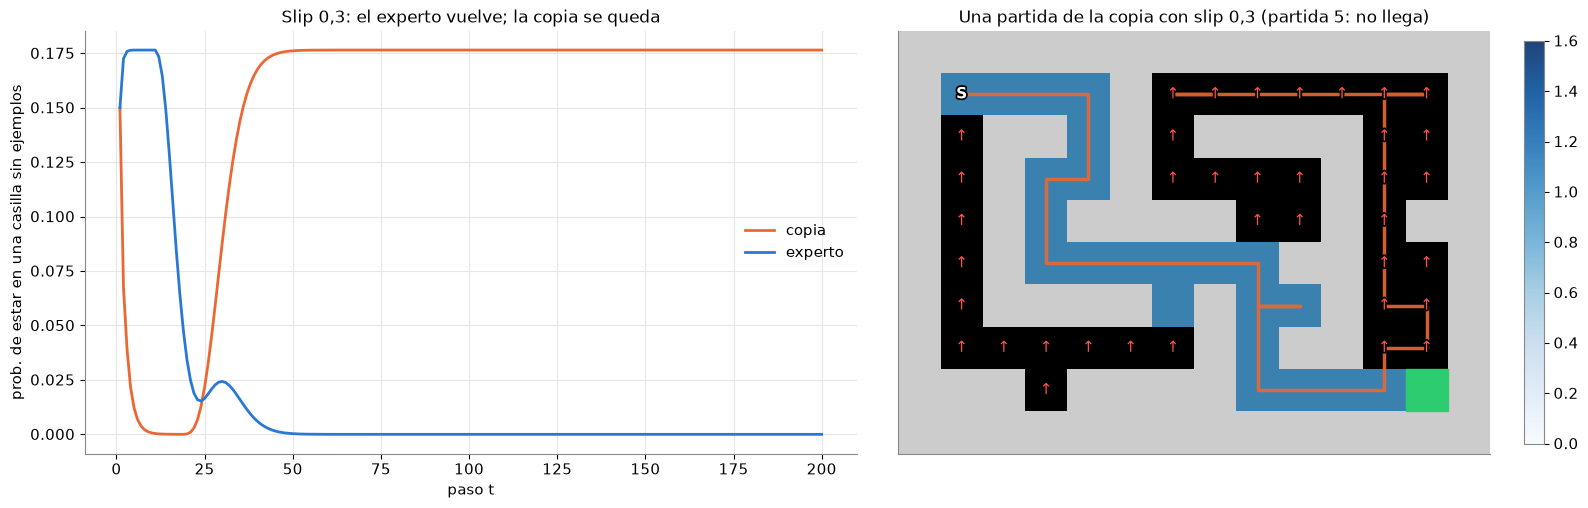

slip 0,3, conjunto 0: copia sale con prob. 0.824, experto 1.000
prob. de estar fuera de lo cubierto en t = 25, 50, 100, 200:   copia 0.022, 0.176, 0.176, 0.176   experto 0.016, 0.000, 0.000, 0.000
la partida dibujada: 200 pasos, 176 en casillas sin ejemplos; primera casilla sin ejemplos en el paso 25: (7, 11); donde terminó: (1, 7)


In [11]:
env3 = CaveEnv(slip=0.3)
mc3, me3 = medir(env3, copia_0, cub_0), medir(env3, pol_exp, cub_0)
# una partida de la copia que no llega (la primera que encontremos)
for k in range(200):
    p_falla = jugar_politica(env3, copia_0, 1, semilla=k)[0]
    if retorno(p_falla) == 0:
        break
cam = camino(p_falla); sin_ej = [s for s in cam if not cub_0[s]]

fig, axs = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
t = np.arange(1, 201)
axs[0].plot(t, mc3["masa"], color=COL_COPIA, label="copia")
axs[0].plot(t, me3["masa"], color=COL_EXP, label="experto")
axs[0].set_xlabel("paso t"); axs[0].set_ylabel("prob. de estar en una casilla sin ejemplos")
axs[0].set_title("Slip 0,3: el experto vuelve; la copia se queda"); axs[0].legend(frameon=False)
plot_cave(env, values=np.where(cub_0, 1.0, np.nan), ax=axs[1], cmap="Blues", clim=(0, 1.6),
          title=f"Una partida de la copia con slip 0,3 (partida {k}: no llega)")
flechas(env, axs[1], copia_0, np.flatnonzero(~cub_0), color="#ff5050")
dibujar_camino(env, axs[1], cam, COL_COPIA)
plt.tight_layout(); plt.show()

print(f"slip 0,3, conjunto 0: copia sale con prob. {mc3['exito']:.3f}, experto {me3['exito']:.3f}")
print(f"prob. de estar fuera de lo cubierto en t = 25, 50, 100, 200:   copia "
      + ", ".join(f"{mc3['masa'][x - 1]:.3f}" for x in [25, 50, 100, 200])
      + "   experto " + ", ".join(f"{me3['masa'][x - 1]:.3f}" for x in [25, 50, 100, 200]))
print(f"la partida dibujada: {len(cam) - 1} pasos, {len(sin_ej)} en casillas sin ejemplos; "
      f"primera casilla sin ejemplos en el paso {next(i for i, s in enumerate(cam) if not cub_0[s])}: "
      f"{env.free[next(s for s in cam if not cub_0[s])]}; donde terminó: {env.free[cam[-1]]}")

Las dos curvas cuentan historias distintas. Al principio la del experto sube: si se resbala hacia abajo en S, sigue por el pasillo de la izquierda, que no está en estos registros, y después de unos 20 pasos vuelve a casillas conocidas y la curva baja a 0. La copia, en esa misma casilla, aprieta ↑ y vuelve a S (esta vez ↑ la ayuda, de casualidad). Pero a partir del paso 20 su curva sube y se queda en 0,176 para siempre: es la probabilidad de quedar atrapada, y coincide con la que le falta para salir (0,824).

La partida dibujada va bien hasta el paso 25: un resbalón en el último pasillo la sube a (7, 11), una casilla sin ejemplos. Ahí aprieta ↑, y en la siguiente también, y así sube por el pasillo de la derecha hasta el de arriba, donde se queda empujando ↑ contra la pared: 176 de sus 200 pasos en casillas sin ejemplos. Un solo desvío chico, y cada paso siguiente la aleja más.

## 4. DAgger: preguntarle al experto donde me equivoqué

Si el problema es que no hay ejemplos donde la copia se desvía, la solución es conseguirlos **justo ahí**. DAgger (*Dataset Aggregation*; Ross, Gordon y Bagnell, 2011) repite tres pasos:

1. Jugar con la copia (al principio, con un poco de ayuda del experto).
2. En cada casilla que se pisó, preguntarle al experto qué flecha habría apretado.
3. Sumar esos ejemplos a la tabla y volver a copiar.

El experto no juega esas partidas: solo **etiqueta** las casillas a las que llegó la copia. Probamos en la cueva de slip 0,3, donde la copia fallaba. En la ronda $k$, el experto maneja con probabilidad $0{,}5^k$ (la mezcla que proponen Ross y coautores) y la copia el resto.

### Paso 1 — Una ronda, a mano

In [12]:
RONDAS, N_RONDA = 5, 20
copias_d, tablas_d, etiq_d = dagger(env3, pol_exp, exp_0, RONDAS, N_RONDA, semilla=SEMILLA)
cub_r = [t.sum(1) > 0 for t in tablas_d]
nuevas = np.flatnonzero(cub_r[1] & ~cub_r[0])
print(f"ronda 0: copia de las 20 partidas grabadas, casillas con ejemplos = {int(cub_r[0][ng].sum())}")
print(f"ronda 1: se jugaron {N_RONDA} partidas, se pidieron {etiq_d[0]} etiquetas al experto, "
      f"casillas nuevas = {len(nuevas)}: {', '.join(str(env.free[s]) for s in nuevas)}")
print("las etiquetas que puso el experto en esas casillas: "
      + ", ".join(f"{env.free[s]} {ACTION_NAMES[pol_exp[s]]}" for s in nuevas))

ronda 0: copia de las 20 partidas grabadas, casillas con ejemplos = 22
ronda 1: se jugaron 20 partidas, se pidieron 727 etiquetas al experto, casillas nuevas = 15: (1, 10), (1, 11), (1, 12), (2, 1), (2, 11), (2, 12), (3, 11), (3, 12), (4, 11), (5, 11), (5, 12), (6, 11), (6, 12), (7, 11), (7, 12)
las etiquetas que puso el experto en esas casillas: (1, 10) →, (1, 11) ↓, (1, 12) ↓, (2, 1) ↓, (2, 11) ↓, (2, 12) ↓, (3, 11) ↓, (3, 12) ←, (4, 11) ↓, (5, 11) ↓, (5, 12) ↓, (6, 11) ↓, (6, 12) ↓, (7, 11) ↓, (7, 12) ↓


### Paso 2 — Ronda por ronda

Comparamos DAgger con dos maneras de conseguir más datos **sin** preguntar donde se equivoca la copia: sumar 20 partidas grabadas del experto por ronda, como las primeras (slip 0,1), o grabarlas en la cueva de prueba (slip 0,3).

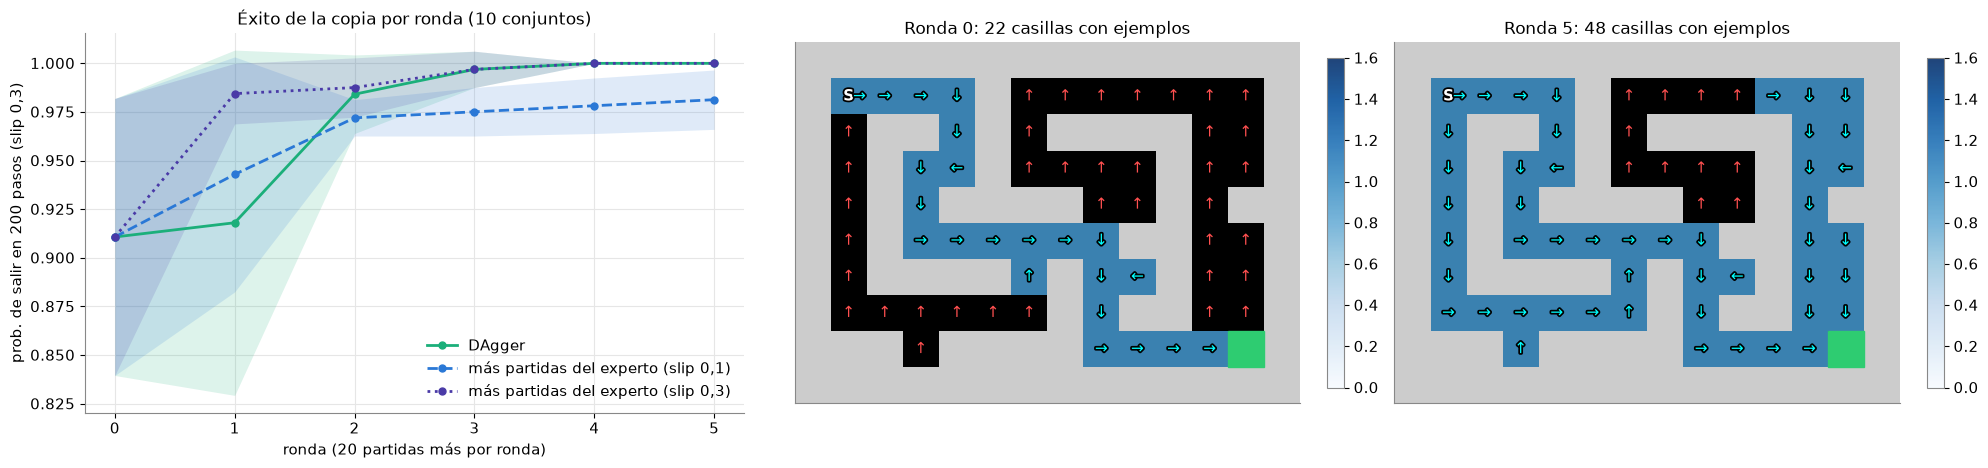

 ronda   DAgger  casillas  etiquetas  +exp slip 0,1  +exp slip 0,3  DAgger sin ayuda
     0    0.911      26.3          —          0.911          0.911             0.911
     1    0.918      33.7        668          0.943          0.984             0.885
     2    0.984      37.9        762          0.972          0.988             0.888
     3    0.997      40.9        694          0.975          0.997             0.891
     4    1.000      42.7        654          0.978          1.000             0.894
     5    1.000      42.7        650          0.981          1.000             0.970

peor conjunto, ronda 0 y ronda 5:  DAgger 0.824 -> 1.000   +exp slip 0,1 0.969   +exp slip 0,3 1.000


In [13]:
exito_d = np.zeros((len(SEMILLAS), RONDAS + 1)); cubre_d = np.zeros_like(exito_d)
exito_b1 = np.zeros_like(exito_d); exito_b3 = np.zeros_like(exito_d); exito_d0 = np.zeros_like(exito_d)
etiquetas_d = np.zeros((len(SEMILLAS), RONDAS))
for i, sem in enumerate(SEMILLAS):
    base = grabar(env, pol_exp, 0.0, N_PARTIDAS, sem)
    cps, tbs, et = dagger(env3, pol_exp, base, RONDAS, N_RONDA, semilla=sem)
    exito_d[i] = [medir(env3, c)["exito"] for c in cps]; cubre_d[i] = [(t.sum(1) > 0)[ng].sum() for t in tbs]
    etiquetas_d[i] = et
    exito_d0[i] = [medir(env3, c)["exito"] for c in dagger(env3, pol_exp, base, RONDAS, N_RONDA, semilla=sem, beta=0)[0]]
    extra1 = grabar(CaveEnv(slip=SLIP), pol_exp, 0.0, N_RONDA * RONDAS, 500 + sem)
    extra3 = grabar(CaveEnv(slip=0.3), pol_exp, 0.0, N_RONDA * RONDAS, 500 + sem)
    for k in range(RONDAS + 1):
        exito_b1[i, k] = medir(env3, copia_mas_frecuente(conteos(env, base + extra1[:N_RONDA * k])))["exito"]
        exito_b3[i, k] = medir(env3, copia_mas_frecuente(conteos(env, base + extra3[:N_RONDA * k])))["exito"]

rondas = np.arange(RONDAS + 1)
fig, axs = plt.subplots(1, 3, figsize=(20, 4.8), gridspec_kw={"width_ratios": [1.2, 1, 1]})
banda(axs[0], rondas, exito_d, COL_OFF, "DAgger")
banda(axs[0], rondas, exito_b1, COL_EXP, "más partidas del experto (slip 0,1)", ls="--")
banda(axs[0], rondas, exito_b3, COL_FILT, "más partidas del experto (slip 0,3)", ls=":")
axs[0].set_xlabel("ronda (20 partidas más por ronda)"); axs[0].set_ylabel("prob. de salir en 200 pasos (slip 0,3)")
axs[0].set_title("Éxito de la copia por ronda (10 conjuntos)"); axs[0].legend(frameon=False, loc="lower right")
for ax, k in [(axs[1], 0), (axs[2], RONDAS)]:
    plot_cave(env, values=np.where(cub_r[k], 1.0, np.nan), ax=ax, cmap="Blues", clim=(0, 1.6),
              title=f"Ronda {k}: {int(cub_r[k][ng].sum())} casillas con ejemplos")
    flechas(env, ax, copias_d[k], np.flatnonzero(cub_r[k]), color="cyan")
    flechas(env, ax, copias_d[k], np.flatnonzero(~cub_r[k]), color="#ff5050")
plt.tight_layout(); plt.show()

print(f"{'ronda':>6s} {'DAgger':>8s} {'casillas':>9s} {'etiquetas':>10s} {'+exp slip 0,1':>14s} {'+exp slip 0,3':>14s} {'DAgger sin ayuda':>17s}")
for k in rondas:
    et = f"{etiquetas_d[:, k - 1].mean():.0f}" if k > 0 else "—"
    print(f"{k:>6d} {exito_d[:, k].mean():>8.3f} {cubre_d[:, k].mean():>9.1f} {et:>10s} {exito_b1[:, k].mean():>14.3f} "
          f"{exito_b3[:, k].mean():>14.3f} {exito_d0[:, k].mean():>17.3f}")
print(f"\npeor conjunto, ronda 0 y ronda {RONDAS}:  DAgger {exito_d[:, 0].min():.3f} -> {exito_d[:, -1].min():.3f}   "
      f"+exp slip 0,1 {exito_b1[:, -1].min():.3f}   +exp slip 0,3 {exito_b3[:, -1].min():.3f}")

Con DAgger, la copia pasa de 0,911 a 0,984 en la ronda 2 y a **1,000 en la ronda 4**, en los 10 conjuntos (el peor pasa de 0,824 a 1,000). Las casillas con ejemplos pasan de 26,3 a 42,7: justo las que la copia pisa. En el dibujo de la ronda 5 quedan sin ejemplos (en rojo) solo casillas a las que la copia casi nunca llega.

Las comparaciones dicen algo importante:

- **Más partidas del experto grabadas como las primeras** llega a 0,981 en la ronda 5: con slip 0,1 el experto casi no se resbala y no visita las casillas donde la copia se pierde.
- **Grabar al experto en la cueva de prueba** (slip 0,3) anda tan bien como DAgger: en esta cueva el experto se resbala igual que la copia, y sus partidas muestran cómo volver. DAgger sirve cuando eso no se puede: cuando no se puede poner al experto en las condiciones nuevas, o cuando la copia se equivoca por su cuenta y llega adonde el experto nunca iría.
- DAgger pide más etiquetas: entre 650 y 760 por ronda, contra unas 450 en 20 partidas del experto, porque una copia trabada pisa muchas veces las mismas casillas.
- **Sin la ayuda del experto** en las primeras rondas (última columna), DAgger avanza de a una casilla por ronda: la copia queda yendo y viniendo entre la última casilla corregida y la siguiente, y solo esa se etiqueta.

## 5. Q-learning offline: aprender solo de lo que ya pasó

Imitar necesita un experto. ¿Y si solo tenemos las partidas **mezcladas**, de gente que casi siempre juega al azar? Copiarlas sería copiar el azar. Pero esas partidas traen algo que la imitación no usa: **la recompensa**. Se sabe cuáles llegaron a la salida y por dónde.

El **Q-learning de la clase 6** no necesita que la acción grabada sea buena: es *off-policy*, aprende el valor de la mejor política aunque los datos vengan de otra. Así que lo corremos sobre el conjunto fijo de transiciones grabadas, una y otra vez, **sin jugar nunca**: eso es **RL offline** (*offline RL*, o *batch RL*; Levine y coautores, 2020). Es el *replay buffer* de la clase 8, pero sin renovarse jamás.

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[r + \gamma \max_{a'} Q(s', a') - Q(s,a)\big]$$

### Paso 1 — Q-learning sobre las 20 partidas mezcladas

La tabla arranca en 0, $\alpha = 0{,}1$ y recorremos las transiciones 60 veces, en orden al azar.

transiciones grabadas = 2534   actualizaciones = 60 × 2534 = 152040   partidas jugadas por el que aprende = 0
partidas mezcladas que llegaron: 17 de 20   la mejor tardó 48 pasos (retorno 0.6235)
max Q(S) aprendido = 0.8062   V*(S) = 0.8032
la política aprendida sale con prob. 0.9998   retorno real = 0.8029
flechas óptimas en 41 de 45 casillas con ejemplos


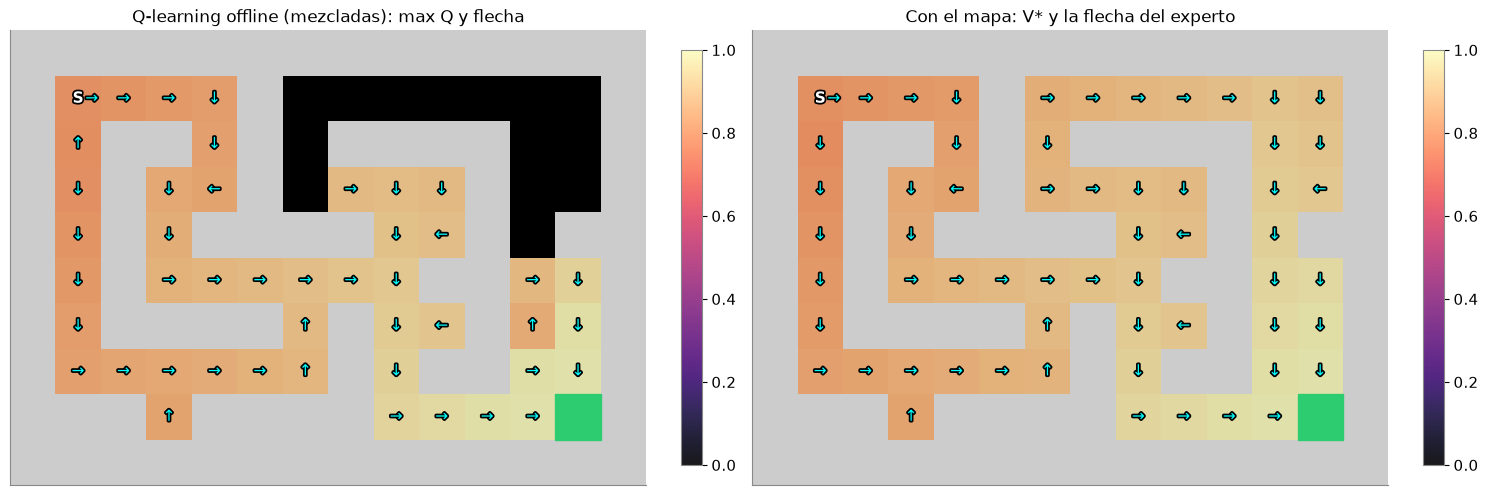

In [14]:
Q_mix, visto_mix = q_offline(env, mix_0, q0=0.0, semilla=SEMILLA)
pi_off = politica_de_Q(Q_mix)
m_off = medir(env, pi_off)
cub_mix0 = visto_mix.any(axis=1)
opt = np.isclose(Q_estrella, Q_estrella.max(axis=1, keepdims=True), rtol=0, atol=1e-9)
bien = [s for s in np.flatnonzero(cub_mix0 & ng) if opt[s, pi_off[s].argmax()]]
n_trans = sum(len(p) for p in mix_0)

print(f"transiciones grabadas = {n_trans}   actualizaciones = 60 × {n_trans} = {60 * n_trans}   partidas jugadas por el que aprende = 0")
print(f"partidas mezcladas que llegaron: {sum(retorno(p) > 0 for p in mix_0)} de {len(mix_0)}   "
      f"la mejor tardó {min(len(p) for p in mix_0 if retorno(p) > 0)} pasos (retorno {max(retorno(p) for p in mix_0):.4f})")
print(f"max Q(S) aprendido = {Q_mix[env.start].max():.4f}   V*(S) = {V_estrella[env.start]:.4f}")
print(f"la política aprendida sale con prob. {m_off['exito']:.4f}   retorno real = {m_off['retorno']:.4f}")
print(f"flechas óptimas en {len(bien)} de {int((cub_mix0 & ng).sum())} casillas con ejemplos")

fig, axs = plt.subplots(1, 2, figsize=(15, 5.4))
plot_cave(env, values=np.where(cub_mix0, Q_mix.max(axis=1), np.nan), ax=axs[0], clim=(0, 1),
          title="Q-learning offline (mezcladas): max Q y flecha")
flechas(env, axs[0], pi_off, np.flatnonzero(cub_mix0))
plot_cave(env, values=V_estrella, ax=axs[1], clim=(0, 1), title="Con el mapa: V* y la flecha del experto")
flechas(env, axs[1], pol_exp, range(env.nS))
plt.tight_layout(); plt.show()

Sin jugar ni una partida, la política aprendida sale con probabilidad 0,9998 y vale 0,8029, casi $V^*(S) = 0{,}8032$. La flecha es óptima en 41 de las 45 casillas con ejemplos. Y ninguna partida grabada fue tan buena: la mejor tardó 48 pasos (retorno 0,6235). Los dos mapas coinciden en las casillas que aparecen en los registros; las negras, sin ejemplos, quedan en 0.

Un detalle: el agente cree que S vale 0,8062, un poco más de lo que vale. Vamos a volver sobre eso en la sección 6.

### Paso 2 — En 10 conjuntos, con las partidas mezcladas y con las del experto

In [15]:
fil5 = {"mezcladas": [], "experto": []}
for sem in SEMILLAS:
    for nombre, eps in [("mezcladas", EPS_MIX), ("experto", 0.0)]:
        parts = grabar(env, pol_exp, eps, N_PARTIDAS, sem)
        Q_, _ = q_offline(env, parts, q0=0.0, semilla=sem)
        m = medir(env, politica_de_Q(Q_))
        fil5[nombre].append((m["exito"], m["retorno"], Q_[env.start].max()))
for nombre, f in fil5.items():
    f = np.array(f)
    print(f"{nombre:10s} sale = {f[:, 0].mean():.3f} (peor {f[:, 0].min():.3f})   retorno real = {f[:, 1].mean():.4f}   "
          f"max Q(S) = {f[:, 2].mean():.4f}   (V*(S) = {V_estrella[env.start]:.4f})")

mezcladas  sale = 1.000 (peor 0.997)   retorno real = 0.8029   max Q(S) = 0.8045   (V*(S) = 0.8032)
experto    sale = 0.977 (peor 0.947)   retorno real = 0.7819   max Q(S) = 0.7866   (V*(S) = 0.8032)


Con las mezcladas, Q-learning offline sale en los 10 conjuntos (el peor, con probabilidad 0,997) y vale 0,8029 en promedio. Con las del experto vale 0,7819, lo mismo que la copia de la sección 2. Si los registros tienen una sola flecha por casilla, no hay nada que elegir: Q-learning offline no tiene cómo saber qué pasa con las otras. **RL offline saca provecho de los datos variados; imitar, de los datos buenos.**

## 6. El cambio de distribución: el optimismo de lo que nunca se probó

Q-learning offline tiene una trampa. La regla usa $\max_{a'} Q(s', a')$ sobre **las cuatro** flechas, pero los registros pueden no tener ningún ejemplo de algunas. El valor de esas acciones **nunca se corrige**: queda en lo que haya puesto la tabla al arrancar. En la clase 6 eso no importaba, porque el agente seguía jugando: si una flecha parecía buena, la probaba y se enteraba. Offline no hay forma de enterarse.

A esto se lo llama **cambio de distribución** (*distribution shift*): la política aprendida quiere hacer cosas que no aparecen en los datos con los que se aprendió.

### Paso 1 — Qué acciones aparecen en los registros

Para cada casilla, cuántas de las cuatro flechas aparecen al menos una vez.

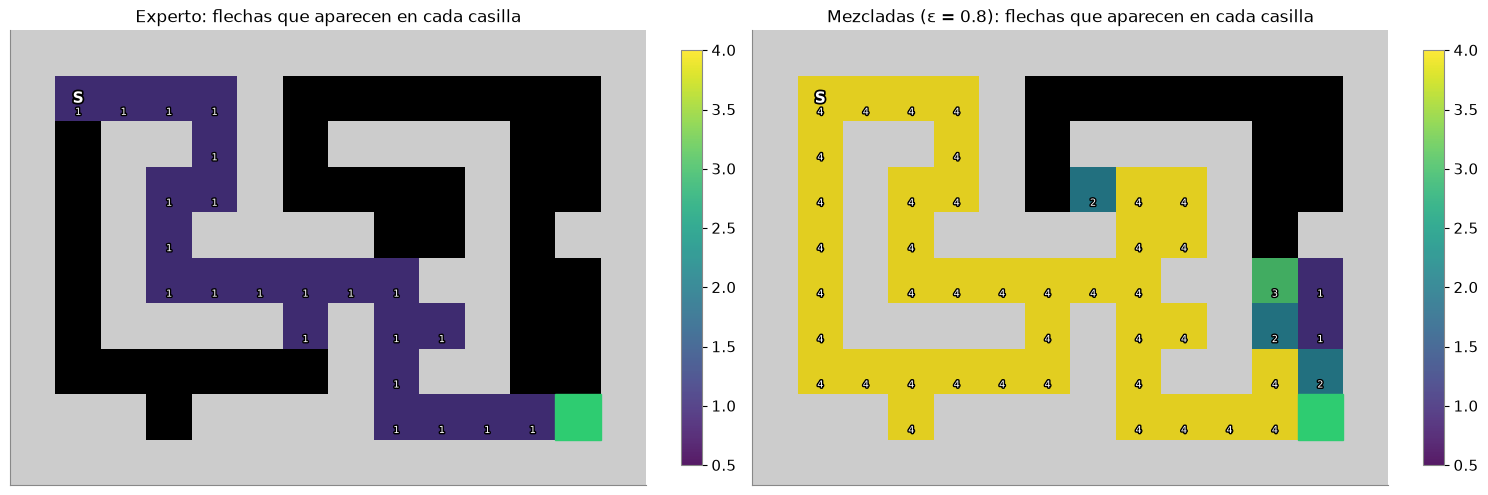

experto    casillas con ejemplos = 22   pares (casilla, acción) que nunca aparecen en esas casillas = 66 de 88
mezcladas  casillas con ejemplos = 45   pares (casilla, acción) que nunca aparecen en esas casillas = 13 de 180


In [16]:
visto_exp = conteos(env, exp_0) > 0
fig, axs = plt.subplots(1, 2, figsize=(15, 5.4))
for ax, v, nombre in [(axs[0], visto_exp, "Experto"), (axs[1], visto_mix, f"Mezcladas (ε = {EPS_MIX})")]:
    n_acc = v.sum(axis=1).astype(float)
    plot_cave(env, values=np.where(n_acc > 0, n_acc, np.nan), ax=ax, cmap="viridis", clim=(0.5, 4), numbers=True, fmt="{:.0f}",
              title=f"{nombre}: flechas que aparecen en cada casilla")
plt.tight_layout(); plt.show()
for nombre, v in [("experto", visto_exp), ("mezcladas", visto_mix)]:
    hay = v.any(axis=1) & ng
    print(f"{nombre:10s} casillas con ejemplos = {int(hay.sum())}   pares (casilla, acción) que nunca aparecen en esas casillas = "
          f"{int((~v[hay]).sum())} de {int(hay.sum()) * 4}")

### Paso 2 — Con qué valor arranca la tabla

Probamos tres maneras de arrancar $Q$:

- **0**: el peor valor posible en esta cueva (no hay premios negativos). Una acción sin ejemplos vale 0 y nunca le gana a una que se vio llegar.
- **1**: optimista, el valor máximo posible.
- **Al azar entre 0 y 1**: como una red neuronal (clase 8), que para una entrada que nunca vio da *algún* número.

Para cada caso contamos en cuántas casillas con ejemplos la política aprendida **quiere una flecha que no aparece en los registros**, y comparamos lo que el agente **cree** que vale S ($\max_a Q(S, a)$) con lo que **de verdad** vale su política ($V^\pi(S)$, medido con el mapa). La diferencia es la **sobreestimación**.

In [17]:
INICIOS = {"0": lambda rng: 0.0, "1": lambda rng: 1.0, "azar": lambda rng: rng.uniform(0, 1, (env.nS, env.nA))}
res6 = {}
for datos, eps in [("experto", 0.0), ("mezcladas", EPS_MIX)]:
    for ini, f0 in INICIOS.items():
        filas = []
        for sem in SEMILLAS:
            parts = grabar(env, pol_exp, eps, N_PARTIDAS, sem)
            Q_, v_ = q_offline(env, parts, q0=f0(np.random.default_rng(100 + sem)), semilla=sem)
            pi_ = politica_de_Q(Q_); hay = v_.any(axis=1) & ng
            quiere = int(sum(not v_[s, pi_[s].argmax()] for s in np.flatnonzero(hay)))
            m = medir(env, pi_)
            filas.append((quiere, hay.sum(), Q_[env.start].max(), m["retorno"], m["exito"]))
        res6[(datos, ini)] = np.array(filas, float)

print(f"promedio de 10 conjuntos de 20 partidas;  V*(S) = {V_estrella[env.start]:.4f}")
print(f"{'datos':>10s} {'Q inicial':>10s} {'quiere lo no visto':>19s} {'cree max Q(S)':>14s} {'vale V^π(S)':>12s} "
      f"{'sobreestima':>12s} {'sale':>7s}")
for (datos, ini), f in res6.items():
    print(f"{datos:>10s} {ini:>10s} {f[:, 0].mean():>9.1f} de {f[:, 1].mean():>4.1f}  {f[:, 2].mean():>14.4f} {f[:, 3].mean():>12.4f} "
          f"{(f[:, 2] - f[:, 3]).mean():>12.4f} {f[:, 4].mean():>7.3f}")

promedio de 10 conjuntos de 20 partidas;  V*(S) = 0.8032
     datos  Q inicial  quiere lo no visto  cree max Q(S)  vale V^π(S)  sobreestima    sale
   experto          0       0.0 de 26.3          0.7866       0.7819       0.0047   0.977
   experto          1      26.3 de 26.3          1.0000       0.0000       1.0000   0.000
   experto       azar       4.6 de 26.3          0.9441       0.2266       0.7175   0.465
 mezcladas          0       0.0 de 49.9          0.8045       0.8029       0.0016   1.000
 mezcladas          1       7.9 de 49.9          0.8663       0.0000       0.8663   0.000
 mezcladas       azar       1.0 de 49.9          0.8077       0.7226       0.0851   0.900


- **Con la tabla en 0** no pasa nada raro: la política nunca quiere una flecha sin ejemplos y sobreestima apenas (0,0047 con el experto, 0,0016 con las mezcladas). Esa sobreestimación chica es **ruido**: con $\alpha$ fijo los valores tiemblan un poco, y el máximo tiende a quedarse con el que salió más alto.
- **Con la tabla en 1**, la catástrofe. Con el experto, en todas las casillas con ejemplos (26,3 en promedio) la política quiere una flecha que nadie grabó: cree que S vale 1 y en realidad vale 0, porque no sale nunca. Con las mezcladas, solo 7,9 de 49,9 casillas quieren algo no grabado, y alcanza para que no salga nunca: el valor inventado **se contagia** por el máximo a las casillas vecinas, y la política entera se desvía hacia esas flechas que nadie probó.
- **Con valores al azar**, como una red, depende de dónde caigan los números: con el experto cree 0,9441 y vale 0,2266 (sale en el 46,5 % de los casos); con las mezcladas cree 0,8077 y vale 0,7226.

Cuantas menos acciones cubren los registros, peor: las partidas del experto, que eran las mejores para imitar, son las más peligrosas para RL offline.

### Paso 3 — Lo que quiere hacer contra lo que está cubierto

Con las partidas del experto y la tabla arrancando en 1: en verde, las casillas donde la flecha aprendida aparece en los registros; en rojo, donde la política quiere una flecha que nadie probó. A la derecha, la misma tabla pero con el máximo restringido a las flechas que **sí** aparecen en los registros, la idea de los métodos offline llamados conservadores.

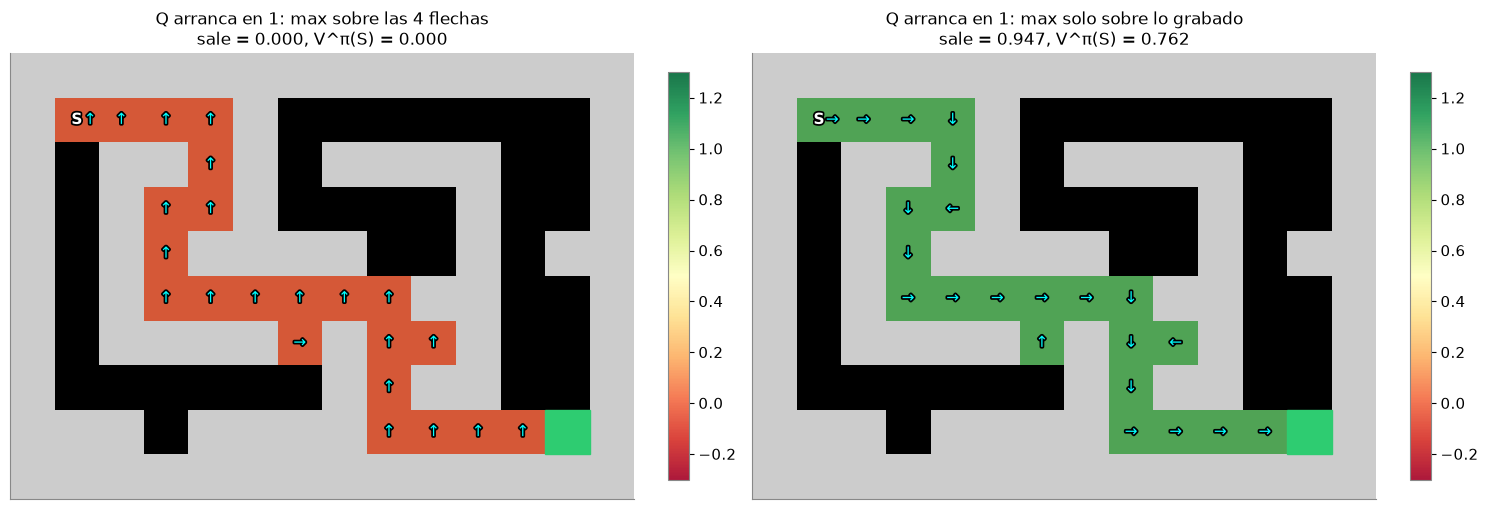

max sobre las 4            quiere lo no visto en 22 de 22 casillas   cree Q(S, flecha elegida) = 1.0000   vale V^π(S) = 0.0000   sale = 0.000
max solo sobre lo grabado  quiere lo no visto en  0 de 22 casillas   cree Q(S, flecha elegida) = 0.8059   vale V^π(S) = 0.7617   sale = 0.947

los 4 valores de S con la tabla arrancando en 1 (max sobre las 4):  ↑ 1.0000 (nunca grabada)   → 0.9900   ↓ 1.0000 (nunca grabada)   ← 1.0000 (nunca grabada)


In [18]:
Q_opt1, _ = q_offline(env, exp_0, q0=1.0, semilla=SEMILLA)
pi_opt1 = politica_de_Q(Q_opt1)
Q_res, _ = q_offline(env, exp_0, q0=1.0, semilla=SEMILLA, solo_vistas=True)
pi_res = politica_de_Q(Q_res, visto_exp, solo_vistas=True)
hay = visto_exp.any(axis=1) & ng

fig, axs = plt.subplots(1, 2, figsize=(15, 5.4))
for ax, pi_, nombre in [(axs[0], pi_opt1, "Q arranca en 1: max sobre las 4 flechas"),
                        (axs[1], pi_res, "Q arranca en 1: max solo sobre lo grabado")]:
    ok = np.array([visto_exp[s, pi_[s].argmax()] if hay[s] else np.nan for s in range(env.nS)], float)
    m = medir(env, pi_)
    plot_cave(env, values=ok, ax=ax, cmap="RdYlGn", clim=(-0.3, 1.3),
              title=f"{nombre}\nsale = {m['exito']:.3f}, V^π(S) = {m['retorno']:.3f}")
    flechas(env, ax, pi_, np.flatnonzero(hay))
plt.tight_layout(); plt.show()

for nombre, Q_, pi_ in [("max sobre las 4", Q_opt1, pi_opt1), ("max solo sobre lo grabado", Q_res, pi_res)]:
    quiere = int(sum(not visto_exp[s, pi_[s].argmax()] for s in np.flatnonzero(hay)))
    m = medir(env, pi_)
    print(f"{nombre:26s} quiere lo no visto en {quiere:2d} de {int(hay.sum())} casillas   cree Q(S, flecha elegida) = {Q_[env.start, pi_[env.start].argmax()]:.4f}   "
          f"vale V^π(S) = {m['retorno']:.4f}   sale = {m['exito']:.3f}")
print("\nlos 4 valores de S con la tabla arrancando en 1 (max sobre las 4):  "
      + "   ".join(f"{ACTION_NAMES[a]} {Q_opt1[env.start, a]:.4f}{'' if visto_exp[env.start, a] else ' (nunca grabada)'}" for a in range(4)))

A la izquierda, todo en rojo: en S, la flecha → (la del experto) vale 0,99 y las otras tres, que nadie grabó, siguen valiendo 1; `argmax` elige la primera de las empatadas, ↑, contra la pared. A la derecha, con el máximo restringido a lo grabado, la política vuelve a ser la del experto y sale con 0,947, como la copia. Aun así cree que S vale 0,8059 y vale 0,7617: cuando se resbala a una casilla que no está en los registros, esa casilla sigue valiendo 1.

Esa es la idea de los métodos de RL offline actuales: **no confiar en acciones que no están en los datos**. Unos restringen la política a lo que se vio; otros castigan el valor de lo no visto (CQL), o aprenden sin preguntar nunca por acciones fuera de los datos (IQL) (Levine y coautores, 2020; CS224R, clase 7). Otro problema cercano, que acá solo mencionamos, es **evaluar** una política nueva sin jugarla, con muestreo por importancia (*importance sampling*).

## 7. Imitar o mejorar: registros buenos y mezclados

Juntamos todo. Tres montones de 20 partidas:

- **Experto**: el de siempre.
- **Mezcladas**: todos juegan con $\varepsilon = 0{,}8$.
- **Mezcla de jugadores**: cada partida es de alguien distinto, con su propio $\varepsilon$ al azar entre 0 y 1; hay quien juega casi como el experto y quien juega casi al azar.

Y cuatro maneras de aprender:

- **Imitar (la más frecuente)**: la copia de la sección 2.
- **Imitar (proporcional)**: la copia fiel, que en cada casilla aprieta cada flecha con la frecuencia con que aparece en los registros. Es lo que aprende un clasificador con *softmax*.
- **Imitar filtrando**: la copia de la más frecuente, pero solo con el 25 % de partidas de mayor retorno (5 de 20).
- **Q-learning offline**: el de la sección 5 (tabla en 0).

### Paso 1 — La tabla

retorno real de la política aprendida (V^π(S)), promedio de 10 conjuntos [peor conjunto];  experto: V*(S) = 0.8032
     datos  imitar (la más frecuente)      imitar (proporcional)    imitar filtrando (25 %)         Q-learning offline  mejor partida grabada  llegaron
   experto              0.782 [0.755]              0.782 [0.755]              0.759 [0.755]              0.782 [0.755]                  0.826      20.0
 mezcladas              0.543 [0.000]              0.289 [0.268]              0.262 [0.000]              0.803 [0.801]                  0.557      17.8
 jugadores              0.695 [0.034]              0.436 [0.305]              0.762 [0.755]              0.790 [0.762]                  0.813      16.7

probabilidad de salir en 200 pasos (promedio):
   experto                      0.977                      0.977                      0.952                      0.977
 mezcladas                      0.704                      0.871                      0.489                   

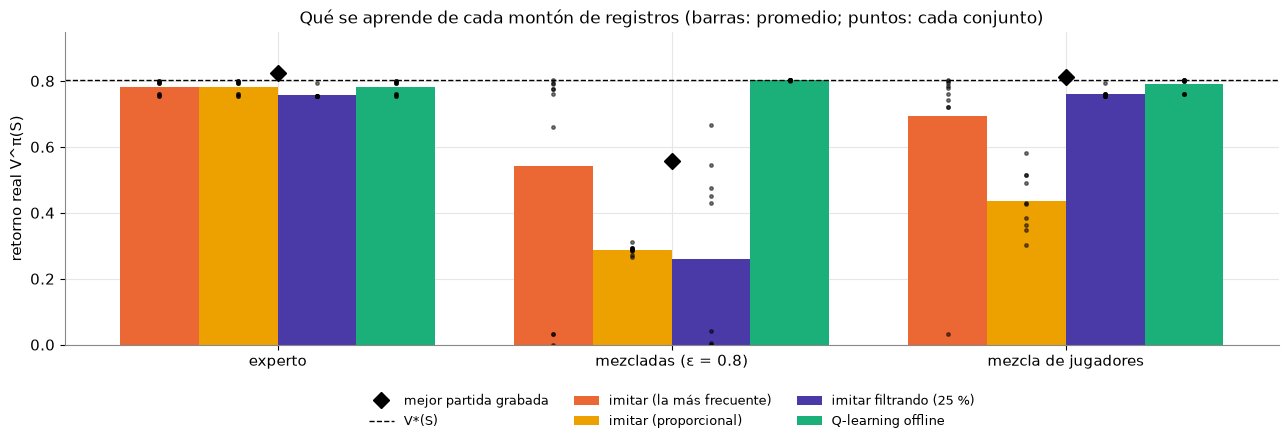

In [19]:
def grabar_jugadores(env, pol, n, semilla):
    rng = np.random.default_rng(semilla)
    return [grabar(env, pol, float(rng.uniform()), 1, 100 * semilla + k)[0] for k in range(n)]

DATOS = {"experto": lambda sem: grabar(env, pol_exp, 0.0, N_PARTIDAS, sem),
         "mezcladas": lambda sem: grabar(env, pol_exp, EPS_MIX, N_PARTIDAS, sem),
         "jugadores": lambda sem: grabar_jugadores(env, pol_exp, N_PARTIDAS, sem)}
METODOS = ["imitar", "proporcional", "filtrar", "offline"]
NOMBRES = {"imitar": "imitar (la más frecuente)", "proporcional": "imitar (proporcional)",
           "filtrar": "imitar filtrando (25 %)", "offline": "Q-learning offline"}

def aprender_todo(parts, sem):
    C = conteos(env, parts)
    Q_, _ = q_offline(env, parts, q0=0.0, semilla=sem)
    pis = {"imitar": copia_mas_frecuente(C), "proporcional": copia_proporcional(C),
           "filtrar": copia_mas_frecuente(conteos(env, mejores(parts))), "offline": politica_de_Q(Q_)}
    return {k: medir(env, p) for k, p in pis.items()}

res7 = {d: {k: [] for k in METODOS + ["mejor partida", "llegaron"]} for d in DATOS}
for d, gen in DATOS.items():
    for sem in SEMILLAS:
        parts = gen(sem)
        for k, m in aprender_todo(parts, sem).items():
            res7[d][k].append((m["retorno"], m["exito"]))
        res7[d]["mejor partida"].append(max(retorno(p) for p in parts))
        res7[d]["llegaron"].append(sum(retorno(p) > 0 for p in parts))

print(f"retorno real de la política aprendida (V^π(S)), promedio de 10 conjuntos [peor conjunto];  experto: V*(S) = {V_estrella[env.start]:.4f}")
print(f"{'datos':>10s} " + " ".join(f"{NOMBRES[k]:>26s}" for k in METODOS) + f" {'mejor partida grabada':>22s} {'llegaron':>9s}")
for d in DATOS:
    celdas = []
    for k in METODOS:
        r = np.array(res7[d][k])[:, 0]
        celdas.append(f"{r.mean():.3f} [{r.min():.3f}]")
    print(f"{d:>10s} " + " ".join(f"{c:>26s}" for c in celdas)
          + f" {np.mean(res7[d]['mejor partida']):>22.3f} {np.mean(res7[d]['llegaron']):>9.1f}")
print("\nprobabilidad de salir en 200 pasos (promedio):")
for d in DATOS:
    print(f"{d:>10s} " + " ".join(f"{np.array(res7[d][k])[:, 1].mean():>26.3f}" for k in METODOS))

fig, ax = plt.subplots(figsize=(13, 4.6))
ancho = 0.2; xs = np.arange(len(DATOS))
for j, (k, col) in enumerate(zip(METODOS, [COL_COPIA, COL_DADO, COL_FILT, COL_OFF])):
    r = np.array([[x[0] for x in res7[d][k]] for d in DATOS])
    ax.bar(xs + (j - 1.5) * ancho, r.mean(1), ancho, color=col, label=NOMBRES[k])
    for i in range(len(DATOS)):
        ax.plot(np.full(len(SEMILLAS), xs[i] + (j - 1.5) * ancho), r[i], "o", color="k", ms=2.5, alpha=0.5)
ax.plot(xs, [np.mean(res7[d]["mejor partida"]) for d in DATOS], "D", color="k", ms=8, label="mejor partida grabada")
ax.axhline(V_estrella[env.start], color="k", ls="--", lw=1, label="V*(S)")
ax.set_xticks(xs); ax.set_xticklabels(["experto", f"mezcladas (ε = {EPS_MIX})", "mezcla de jugadores"])
ax.set_ylabel("retorno real V^π(S)"); ax.set_ylim(0, 0.95)
ax.set_title("Qué se aprende de cada montón de registros (barras: promedio; puntos: cada conjunto)")
ax.legend(frameon=False, ncol=3, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

- **Con solo partidas del experto**, las cuatro maneras dan casi lo mismo (0,782; filtrar da 0,759 porque 5 partidas tocan menos casillas). Imitar alcanza, y RL offline no agrega nada. (La mejor partida grabada vale 0,826, más que $V^*(S)$: es la partida con suerte, sin un solo resbalón. Una política se mide por el promedio, y el promedio no le puede ganar a la partida más afortunada.)
- **Con las mezcladas** ($\varepsilon = 0{,}8$), imitar se cae. La copia proporcional copia también el azar (0,289). La de la más frecuente depende del conjunto (0,543 en promedio, con conjuntos en 0: alguna casilla donde por azar ganó una flecha equivocada, y la copia queda yendo y viniendo). Filtrar tampoco ayuda (0,262): las 5 mejores partidas también son casi al azar, y tocan menos casillas. Q-learning offline llega a 0,803 en todos los conjuntos.
- **Con la mezcla de jugadores**, filtrar sí sirve (0,762, contra 0,695 de imitar todo): las mejores partidas son de los que juegan casi como el experto. Q-learning offline sigue arriba (0,790).

### Paso 2 — Un camino mejor que cualquier partida (*stitching*)

Con las partidas mezcladas, Q-learning offline sale mejor que **la mejor partida grabada**. Ninguna partida hizo el camino corto de un tirón; la política aprendida lo arma con pedazos: un tramo de una partida, otro tramo de otra. A esto se lo llama **coser** trayectos (*stitching*). Lo vemos con el conjunto 0: la mejor partida grabada (con un temblor en el dibujo, para que se vean las idas y vueltas) y el camino de la política aprendida sin resbalones, pintado según la partida de la que sale cada tramo.

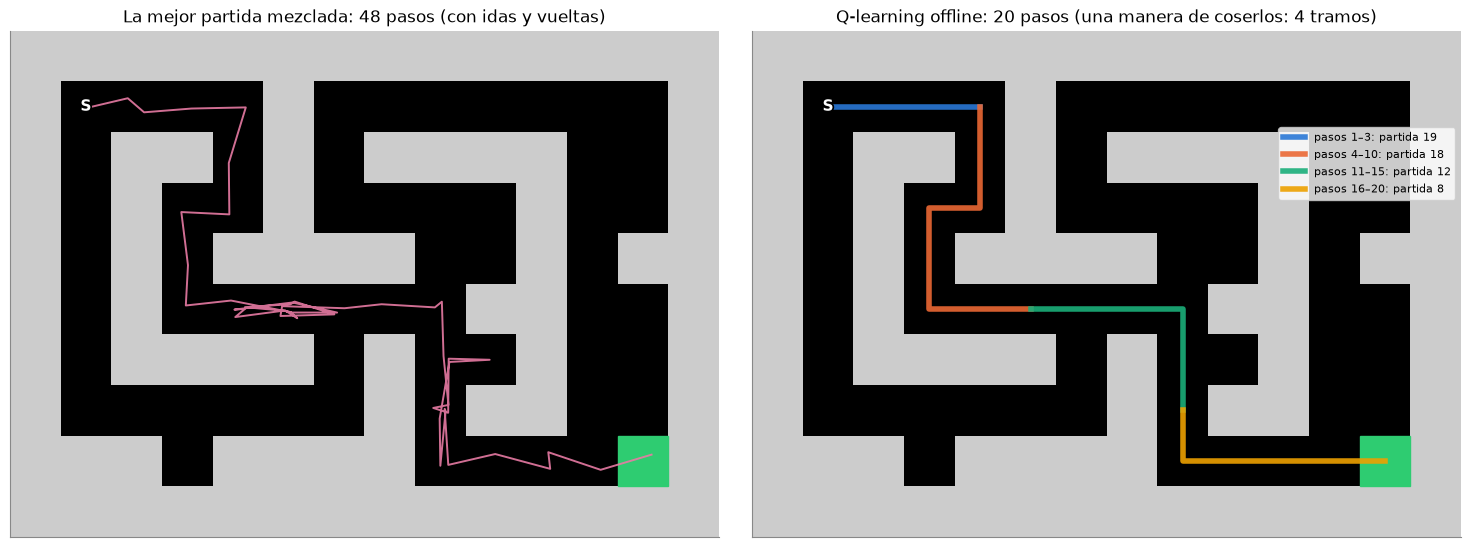

conjunto 0: la mejor partida tardó 48 pasos (retorno 0.6235); la política aprendida vale V^π(S) = 0.8029 con slip 0,1 y hace 20 pasos sin resbalones
tramos: pasos 1–3 de la partida 19;  pasos 4–10 de la partida 18;  pasos 11–15 de la partida 12;  pasos 16–20 de la partida 8
tramo seguido más largo del camino aprendido dentro de una sola partida: 10 de 20 pasos

en los 10 conjuntos (pasos sin resbalones del camino aprendido, tramo más largo en una partida, partida más corta que llegó):
   (20, 10, 48)   (20, 7, 45)   (20, 7, 49)   (20, 6, 75)   (20, 6, 63)   (20, 8, 64)   (20, 5, 54)   (20, 5, 67)   (20, 6, 65)   (20, 6, 66)
en 10 de 10 conjuntos, Q-learning offline vale más que la mejor partida grabada (promedios: 0.803 contra 0.557)


In [20]:
mejor = max(mix_0, key=retorno)
env0 = CaveEnv(slip=0.0)
cam_off = camino(jugar_politica(env0, pi_off, 1, semilla=0)[0])
tramos, mas_largo = coser(mix_0, cam_off)

fig, axs = plt.subplots(1, 2, figsize=(15, 5.4))
plot_cave(env, ax=axs[0], title=f"La mejor partida mezclada: {len(mejor)} pasos (con idas y vueltas)")
dibujar_camino(env, axs[0], camino(mejor), COL_MIX, lw=1.4, temblor=0.18)
plot_cave(env, ax=axs[1], title=f"Q-learning offline: {len(cam_off) - 1} pasos (una manera de coserlos: {len(tramos)} tramos)")
for n_t, (a_, b_, i_p) in enumerate(tramos):
    dibujar_camino(env, axs[1], cam_off[a_:b_ + 1], COLORES[n_t % len(COLORES)], lw=4,
                   label=f"pasos {a_ + 1}–{b_}: partida {i_p}" if i_p is not None else f"pasos {a_ + 1}–{b_}: sin registro")
axs[1].legend(frameon=True, fontsize=8, loc="upper right", bbox_to_anchor=(1.0, 0.82))
plt.tight_layout(); plt.show()

largos_t = []
for sem in SEMILLAS:
    parts = grabar(env, pol_exp, EPS_MIX, N_PARTIDAS, sem)
    Q_, _ = q_offline(env, parts, q0=0.0, semilla=sem)
    c_ = camino(jugar_politica(env0, politica_de_Q(Q_), 1, semilla=0)[0])
    largos_t.append((len(c_) - 1, coser(parts, c_)[1], min(len(p) for p in parts if retorno(p) > 0)))
mejores_ret = np.array(res7["mezcladas"]["mejor partida"]); off_ret = np.array(res7["mezcladas"]["offline"])[:, 0]
print(f"conjunto 0: la mejor partida tardó {len(mejor)} pasos (retorno {retorno(mejor):.4f}); la política aprendida vale "
      f"V^π(S) = {m_off['retorno']:.4f} con slip 0,1 y hace {len(cam_off) - 1} pasos sin resbalones")
print("tramos: " + ";  ".join(f"pasos {a_ + 1}–{b_} de la partida {i_p}" for a_, b_, i_p in tramos))
print(f"tramo seguido más largo del camino aprendido dentro de una sola partida: {mas_largo} de {len(cam_off) - 1} pasos")
print()
print(f"en los 10 conjuntos (pasos sin resbalones del camino aprendido, tramo más largo en una partida, partida más corta que llegó):")
print("   " + "   ".join(f"({a}, {b}, {c})" for a, b, c in largos_t))
print(f"en {int(np.sum(off_ret > mejores_ret))} de {len(SEMILLAS)} conjuntos, Q-learning offline vale más que la mejor partida grabada "
      f"(promedios: {off_ret.mean():.3f} contra {mejores_ret.mean():.3f})")

La mejor partida mezclada iba más o menos por el buen camino, pero con idas y vueltas: 48 pasos. El camino aprendido tiene 20, y ninguna partida lo hizo de un tirón: el tramo seguido más largo que aparece en una sola partida tiene 10 pasos (en los 10 conjuntos, entre 5 y 10 de 20). La política aprendida lo arma con tramos de varias partidas, y en los 10 conjuntos vale más que la mejor partida grabada (0,803 contra 0,557 en promedio).

Imitar no puede hacer esto: imitar copia partidas. RL offline usa la recompensa para quedarse con los tramos que llevan a la salida y descartar el resto.

## ✍️ Ejercicio — Cambien cuántas partidas hay y qué tan buenas

Cambien `n_ej` (cuántas partidas) y `eps_ej` (qué tan al azar juegan: 0 = experto, 1 = al azar) y ejecuten. La celda graba 5 conjuntos, aprende con las cuatro maneras de la sección 7, mide cada política en la cueva de slip 0,1 y en la de slip 0,3 (para ver los errores compuestos), y dibuja las casillas con ejemplos del primer conjunto.

Antes de ejecutar, **predigan**: con `eps_ej = 0` y solo 3 partidas, ¿cuánto pierde la copia con slip 0,3? ¿Y con 100 partidas? Con `eps_ej = 1`, ¿alguna manera aprende algo? ¿Qué necesita Q-learning offline que la imitación no?

n = 5, ε = 0.0: casillas con ejemplos = [20, 33, 21, 20, 21]   partidas que llegaron = [5, 5, 5, 5, 5]
                            sale (slip 0,1)  sale (slip 0,3)
 imitar (la más frecuente)            0.977            0.911
     imitar (proporcional)            0.977            0.911
   imitar filtrando (25 %)            0.957            0.853
        Q-learning offline            0.977            0.911
                   experto            1.000            1.000


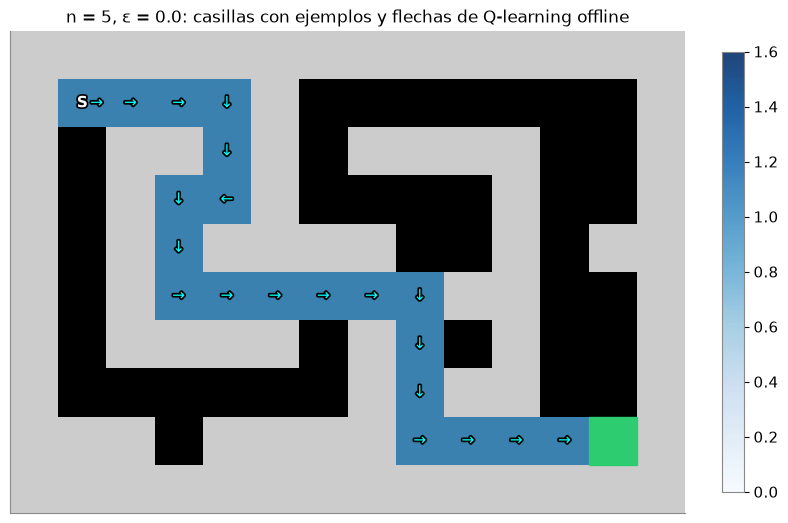

In [21]:
n_ej = 5         # TODO: probá 3, 20, 100
eps_ej = 0.0     # TODO: probá 0.0, 0.5, 0.9, 1.0

tabla_ej = {k: [] for k in METODOS}; cubre_ej = []; llegan_ej = []
for sem in range(5):
    parts = grabar(env, pol_exp, eps_ej, n_ej, sem)
    C = conteos(env, parts); Q_, _ = q_offline(env, parts, q0=0.0, semilla=sem)
    pis = {"imitar": copia_mas_frecuente(C), "proporcional": copia_proporcional(C),
           "filtrar": copia_mas_frecuente(conteos(env, mejores(parts))), "offline": politica_de_Q(Q_)}
    for k, p in pis.items():
        tabla_ej[k].append((medir(env, p)["exito"], medir(env3, p)["exito"]))
    cubre_ej.append(int((C.sum(1) > 0)[ng].sum())); llegan_ej.append(sum(retorno(p) > 0 for p in parts))
    if sem == 0:
        cub_ej = C.sum(1) > 0; pi_ej = pis["offline"]

print(f"n = {n_ej}, ε = {eps_ej}: casillas con ejemplos = {cubre_ej}   partidas que llegaron = {llegan_ej}")
print(f"{'':>26s} {'sale (slip 0,1)':>16s} {'sale (slip 0,3)':>16s}")
for k in METODOS:
    t_ = np.array(tabla_ej[k])
    print(f"{NOMBRES[k]:>26s} {t_[:, 0].mean():>16.3f} {t_[:, 1].mean():>16.3f}")
print(f"{'experto':>26s} {m_exp['exito']:>16.3f} {medir(env3, pol_exp)['exito']:>16.3f}")

fig, ax = plt.subplots(figsize=(8, 5.8))
plot_cave(env, values=np.where(cub_ej, 1.0, np.nan), ax=ax, cmap="Blues", clim=(0, 1.6),
          title=f"n = {n_ej}, ε = {eps_ej}: casillas con ejemplos y flechas de Q-learning offline")
flechas(env, ax, pi_ej, np.flatnonzero(cub_ej))
plt.tight_layout(); plt.show()

**Lo que encontramos** (¿cuántas partidas hacen falta para que la copia aguante el slip 0,3? ¿desde qué $\varepsilon$ imitar deja de servir? ¿cuándo Q-learning offline tampoco puede?):

-

## Preguntas para pensar

1. Un modelo de lenguaje (clase 9) aprende a predecir la próxima palabra de textos escritos por personas: es clonación de comportamiento. ¿Qué serían los errores compuestos cuando escribe una respuesta larga? ¿Y qué sería DAgger?
2. En la sección 6, la tabla que arrancaba en 0 no sobreestimaba porque en la cueva no hay premios negativos. Si cada paso costara −0,01 (como en la clase 4), ¿seguiría siendo 0 un valor «pesimista» para las acciones sin ejemplos?
3. Para Q-learning offline, ¿qué es mejor: 20 partidas del experto o 20 partidas mezcladas? ¿Y para imitar? ¿Qué les dice eso sobre qué registros conviene guardar en un sistema real?

## Próxima clase

Imitar copia lo que hubo; RL offline arma lo mejor que se puede con lo que hubo. Para ir más allá hay que volver a jugar y **reforzar lo que salió bien**: en la clase 11, *policy gradient*, que es como imitar, pero solo las partidas que terminaron bien y en proporción a cuánto.